# 10e Confirm and Report Frozen Concepts

Run only after concept definitions and selection are frozen on development pairs. This notebook evaluates the final catalog on confirmation pairs; do not use these results to revise concepts or choose additional candidates.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipeline_config import cfg, cfg_path, load_pipeline_config
from amr.pipelines.concepts import build_si_concept_paths, load_concept_corpus, corpus_preflight
from amr.si.concepts import (
    SEED_CONCEPTS, concept_catalog_hash, estimate_classification_cost,
    classify_concept_abstracts, build_yearly_concept_signals,
    rolling_origin_concept_forecasts, summarise_incremental_forecast_gains,
    propose_concept_children,
)

PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)
CONCEPT_PATHS = build_si_concept_paths(PROJECT_ROOT)
MODEL_NAME = str(cfg(PIPELINE_CONFIG, "system1.model", "typesafe/jev-1.13"))

corpus = pd.read_parquet(CONCEPT_PATHS["corpus"])
si_df = pd.read_parquet(PROJECT_ROOT / "outputs" / "parquets" / "yearly_si.parquet")
catalog = json.loads(CONCEPT_PATHS["catalog"].read_text())
CATALOG_VERSION = concept_catalog_hash(catalog)
EXPECTED_FROZEN_CATALOG_VERSION = "54d79903b1dbf073"  # frozen nine-seed catalog for this run
CONFIRMATION_ENABLED = True  # confirmation is enabled for the frozen seed catalog
if not CONFIRMATION_ENABLED or EXPECTED_FROZEN_CATALOG_VERSION != CATALOG_VERSION:
    raise RuntimeError("Freeze the catalog, set the expected hash, and explicitly enable confirmation.")
scores = pd.read_parquet(CONCEPT_PATHS["scores"])
valid = scores.loc[
    scores["catalog_version"].astype(str).eq(CATALOG_VERSION)
    & scores["model_name"].astype(str).eq(MODEL_NAME)
    & scores["status"].eq("ok")
]
expected_pmids = set(corpus.loc[corpus["abstract_available"], "pmid"].astype(str))
if expected_pmids - set(valid["pmid"].astype(str)):
    raise RuntimeError("Frozen catalog scores are incomplete; finish notebook 10c first.")
signals = build_yearly_concept_signals(corpus, scores, catalog_version=CATALOG_VERSION, model_name=MODEL_NAME)

# Keep these settings aligned with notebook 10f for directly comparable forecasts.
FIT_START_YEAR = int(cfg(PIPELINE_CONFIG, "si.fit_start_year", 2000))
FORECAST_ORIGIN_END_YEAR = int(cfg(PIPELINE_CONFIG, "si.fit_end_year", 2023))
LAG_LENGTH = 3
FORECAST_HORIZONS = (1, 2, 3)
MIN_PRIOR_OBSERVATIONS = 10
FORECAST_PROGRESS_EVERY = 10


## Configure the frozen model population

This configured run confirms the nine-seed catalog on held-out pairs after development evaluation. The default report evaluates each catalog concept against the SI-only baseline. Populate `FROZEN_POPULATION` with the development-selected set to report leave-one-out conditional gains, and set `FROZEN_PARENT_CHILD_REPLACEMENTS` to confirm parent-to-child-set and individual-child replacements while holding the remaining population fixed. The initial seed catalog is pinned at hash `54d79903b1dbf073`. After the development refinement round, update `EXPECTED_FROZEN_CATALOG_VERSION` to the reviewed final catalog hash before confirmation. The code guard checks the hash; the selected pathogen limit and pair split must match notebooks 10a–10d.

If a definition or selection changes after reviewing confirmation performance, those pairs have become development evidence for that decision. A new independent confirmation set would be needed for a fresh final estimate.

In [2]:
FROZEN_CONCEPT_IDS = [str(concept["concept_id"]) for concept in catalog]
# Copy the development-selected concepts here before confirmation.
FROZEN_POPULATION = []
FROZEN_PARENT_CHILD_REPLACEMENTS = {}  # e.g. {"surveillance": ["genomic_surveillance", "hospital_surveillance"]}
if FROZEN_PARENT_CHILD_REPLACEMENTS and not FROZEN_POPULATION:
    raise ValueError("Set FROZEN_POPULATION before requesting nested replacement estimates.")
if any(parent_id not in FROZEN_POPULATION for parent_id in FROZEN_PARENT_CHILD_REPLACEMENTS):
    raise ValueError("Every nested-replacement parent must be included in FROZEN_POPULATION.")
model_sets = {f"concept:{concept_id}": [concept_id] for concept_id in FROZEN_CONCEPT_IDS}
comparisons = {name: "baseline" for name in model_sets}
if FROZEN_POPULATION:
    model_sets["frozen_population"] = list(FROZEN_POPULATION)
    comparisons["frozen_population"] = "baseline"
    # Leave-one-out conditional confirmation: full population versus population without each concept.
    for concept_id in FROZEN_POPULATION:
        full_name = f"conditional_with:{concept_id}"
        without_name = f"conditional_without:{concept_id}"
        model_sets[full_name] = list(FROZEN_POPULATION)
        model_sets[without_name] = [item for item in FROZEN_POPULATION if item != concept_id]
        comparisons[full_name] = without_name
    # Nested confirmation replaces each parent while holding other selected concepts fixed.
    for parent_id, child_ids in FROZEN_PARENT_CHILD_REPLACEMENTS.items():
        background = [item for item in FROZEN_POPULATION if item != parent_id]
        parent_name = f"nested_parent:{parent_id}"
        children_name = f"nested_children:{parent_id}"
        model_sets[parent_name] = list(FROZEN_POPULATION)
        model_sets[children_name] = [*background, *child_ids]
        comparisons[children_name] = parent_name
        for child_id in child_ids:
            single_name = f"nested_single_child:{parent_id}:{child_id}"
            model_sets[single_name] = [*background, child_id]
            comparisons[single_name] = parent_name


## Held-out rolling-origin confirmation

Shared forecast slopes are learned using development pairs. For each confirmation pair, its intercept is calibrated from that pair's SI history available at each origin; confirmation outcomes do not train shared slopes. Only confirmation-pair forecasts are kept in the final table.

The fixed lag length, direct horizons, eligibility threshold, and MSE loss match notebook 10d, making the development and confirmation summaries comparable.

In [3]:
split = pd.read_csv(CONCEPT_PATHS["pair_split"])
development_pairs = set(map(tuple, split.loc[split["split"].eq("development"), ["pathogen", "antibiotic"]].astype(str).to_numpy()))
confirmation_pairs = set(map(tuple, split.loc[split["split"].eq("confirmation"), ["pathogen", "antibiotic"]].astype(str).to_numpy()))
forecasts = rolling_origin_concept_forecasts(
    si_df, signals, concept_ids=FROZEN_CONCEPT_IDS, model_sets=model_sets,
    development_pairs=development_pairs,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FORECAST_ORIGIN_END_YEAR,
    lag_length=LAG_LENGTH, horizons=FORECAST_HORIZONS, min_prior_observations=MIN_PRIOR_OBSERVATIONS,
)
# Keep confirmation-pair forecasts; historical outcomes are used only to calibrate each pair intercept.
forecasts = forecasts.loc[
    [pair in confirmation_pairs for pair in zip(forecasts["pathogen"].astype(str), forecasts["antibiotic"].astype(str))]
].copy()
forecasts.to_parquet(CONCEPT_PATHS["confirmation_forecasts"], index=False)
pair_summary, population_summary = summarise_incremental_forecast_gains(forecasts, comparisons)
pair_summary.to_parquet(CONCEPT_PATHS["confirmation_summary"], index=False)
population_summary


,model,reference_model,horizon,generality,specialist_strength,pairs
0,concept:agricultural_use,baseline,1,0.000005,0.000841,15
1,concept:agricultural_use,baseline,2,-0.000762,0.000475,15
2,concept:agricultural_use,baseline,3,0.000851,0.003312,14
3,concept:diagnostics,baseline,1,0.000813,0.004810,15
4,concept:diagnostics,baseline,2,0.001070,0.003417,15
5,concept:diagnostics,baseline,3,0.001099,0.006299,14
6,concept:genomic_evidence,baseline,1,-0.000484,0.001337,15
7,concept:genomic_evidence,baseline,2,0.000413,0.002753,15
8,concept:genomic_evidence,baseline,3,0.000086,0.001664,14
9,concept:hospital_transmission,baseline,1,-0.000152,0.002019,15


## Report and plot

The table reports held-out mean gain and specialist strength separately at each configured horizon and as an equal-weight aggregate. The figure shows mean gain by configured horizon; the zero line marks parity with the reference model. Read it alongside horizon rows and confirmation-pair counts. Keep negative results too: they show where the frozen vocabulary does not generalise.

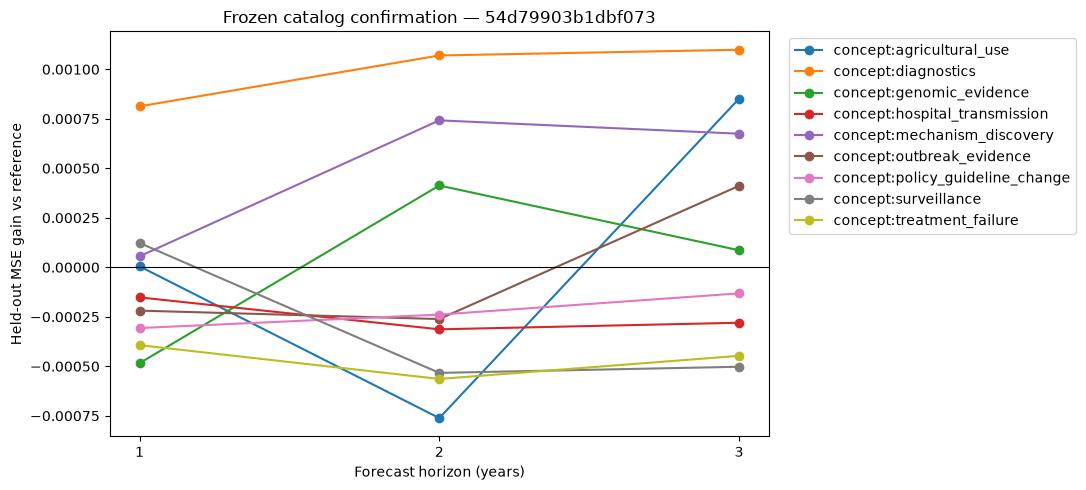

,model,horizon,generality,specialist_strength,confirmation_pairs
0,concept:agricultural_use,1,0.000005,0.000841,15
1,concept:agricultural_use,2,-0.000762,0.000475,15
2,concept:agricultural_use,3,0.000851,0.003312,14
3,concept:diagnostics,1,0.000813,0.004810,15
4,concept:diagnostics,2,0.001070,0.003417,15
5,concept:diagnostics,3,0.001099,0.006299,14
6,concept:genomic_evidence,1,-0.000484,0.001337,15
7,concept:genomic_evidence,2,0.000413,0.002753,15
8,concept:genomic_evidence,3,0.000086,0.001664,14
9,concept:hospital_transmission,1,-0.000152,0.002019,15


In [4]:
import matplotlib.pyplot as plt

horizon_report = pair_summary.groupby(["model", "horizon"], as_index=False).agg(
    generality=("forecast_gain", "mean"),
    specialist_strength=("forecast_gain", lambda values: values.quantile(0.9)),
    confirmation_pairs=("forecast_gain", "count"),
)
CONCEPT_PATHS["figures"].mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(11, 5))
for model, group in horizon_report.groupby("model"):
    ax.plot(group["horizon"], group["generality"], marker="o", label=model)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xticks=[1, 2, 3], xlabel="Forecast horizon (years)", ylabel="Held-out MSE gain vs reference",
       title=f"Frozen catalog confirmation — {CATALOG_VERSION}")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(CONCEPT_PATHS["figures"] / "confirmation_generality_by_horizon.png", dpi=160)
plt.show()
horizon_report
